# Modelo preditor de natimortalidade municipal a partir de dados públicos do SUS

**Pergunta de pesquisa:** com dados públicos do SUS de um período, é possível prever quais municípios brasileiros terão natimortalidade alta
no período seguinte, inclusive em estados que o modelo nunca viu? E isso funciona melhor do que usar o IDHM, que é o indicador mais usado para comparar municípios?

**Desenho em uma frase:** o modelo aprende com os dados de **2008 a 2015** e é testado na natimortalidade de **2016 a 2024**, sempre em um **estado que ficou fora do treino**.

**Roteiro**
1. Variáveis de saída e de entrada (e o que significam os rótulos)
2. Seleção de variáveis: filtro estatístico e seleção progressiva (*forward selection*)
3. Escolha da regressão logística e forma de treino e teste
4. Resultados do teste
5. Testes estatísticos de explicação do modelo
6. Comparação com as referências: IDHM e taxa passada do município

**Arquivos:** este notebook lê `base_treino_2008_2015.csv` e `base_teste_2016_2024.csv`, que estão na mesma pasta, e salva as figuras em `figuras/`.
Pacotes necessários: `pandas numpy matplotlib seaborn scipy scikit-learn statsmodels`. A execução completa leva poucos minutos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
})
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
SEMENTE = 42

PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)


def salvar(nome):
    plt.savefig(PASTA_FIG / f"{nome}.pdf", bbox_inches="tight")

## 1. Variáveis de saída e de entrada

### a) Unidade de análise e períodos
Cada linha das bases é **um município**. Há duas bases, com as mesmas colunas:

| Base | Período | Papel |
|---|---|---|
| `base_treino_2008_2015.csv` | 2008 a 2015 (8 anos) | **treino**: seleção de variáveis e ajuste do modelo |
| `base_teste_2016_2024.csv` | 2016 a 2024 (9 anos) | **teste**: só é usada para conferir as previsões |

Em cada base, os anos do período são agregados: nascimentos e óbitos são **somados**; os percentuais são a **média ponderada** pelos nascidos vivos de cada ano.
Agregar vários anos é necessário porque metade dos municípios tem menos de 100 nascimentos por ano, e nesse tamanho a taxa de um ano só oscila por acaso.

### b) Saída (responde à pergunta de pesquisa)
A taxa de natimortalidade do município no período é

$$\text{TAXA} = \frac{\text{óbitos fetais}}{\text{nascidos vivos} + \text{óbitos fetais}} \times 1000,$$

contando os óbitos fetais com 22 semanas ou mais de gestação ou 500 g ou mais (fonte: SIM, arquivos DOFET).

A saída do modelo é **qualitativa**, com dois rótulos:

| Rótulo | Nome | Significado |
|---|---|---|
| `ALTA = 1` | natimortalidade alta | a taxa do município no período é **maior** que a taxa do seu estado no mesmo período |
| `ALTA = 0` | não alta | a taxa do município é igual ou menor que a taxa do seu estado |

O rótulo é calculado **separadamente em cada período**: o de 2008–2015 serve para treinar; o de 2016–2024 é o que o modelo tenta prever.

O corte é **por estado** (e não um valor único para o país) porque o nível de natimortalidade e a qualidade do registro mudam de estado para estado.
Com um corte nacional, o modelo aprenderia a separar regiões (Norte e Nordeste do Sul), e não municípios. O Distrito Federal é tratado junto com Goiás.

### c) Entradas (todas disponíveis no DATASUS)

| Variável | Significado | Fonte |
|---|---|---|
| `PCT_MAE_ESC_MENOS8` | % de mães com menos de 8 anos de estudo | SINASC (ESCMAE) |
| `PCT_MAE_ADOLESCENTE` | % de mães com 10 a 19 anos | SINASC (IDADEMAE) |
| `PCT_MAE_35MAIS` | % de mães com 35 anos ou mais | SINASC (IDADEMAE) |
| `PCT_PRETA_PARDA` | % de nascidos pretos ou pardos (marcador de desigualdade social) | SINASC (RACACOR) |
| `PCT_PRENATAL_7MAIS` | % de gestantes com 7 ou mais consultas de pré-natal | SINASC (CONSULTAS) |
| `PCT_PRENATAL_1TRIM` | % com pré-natal iniciado no 1º trimestre (2012 em diante) | SINASC (MESPRENAT) |
| `PCT_PRENATAL_ADEQUADO` | % com pré-natal adequado pelo índice de Kotelchuck (2014 em diante) | SINASC (KOTELCHUCK) |
| `PCT_CESAREA` | % de partos cesáreos | SINASC (PARTO) |
| `EQUIPES_ESF_10MIL` | equipes de Saúde da Família por 10 mil habitantes | Relatório APS / e-Gestor AB |
| `LOG_POPULACAO` | população do município (log10) | Relatório APS / e-Gestor AB |

Os percentuais vêm só dos **nascidos vivos** (SINASC) e a saída vem dos **óbitos fetais** (SIM): as entradas não usam nenhuma informação dos óbitos.
O modelo usa as entradas de **2008–2015** para prever a saída de **2016–2024**.
O IDHM de 2010 (Atlas do Desenvolvimento Humano) fica guardado para a comparação da seção 6.

In [2]:
def ler_base(arquivo):
    return pd.read_csv(arquivo, sep=";", decimal=",", dtype={"CODMUNRES": str}).set_index("CODMUNRES")


treino = ler_base("base_treino_2008_2015.csv").dropna(subset=["IDHM"])  # criados depois de 2010 não têm IDHM
teste = ler_base("base_teste_2016_2024.csv").loc[treino.index]          # os mesmos municípios, na mesma ordem

ENTRADAS = {
    "PCT_MAE_ESC_MENOS8": "Mães com < 8 anos de estudo",
    "PCT_MAE_ADOLESCENTE": "Mães adolescentes",
    "PCT_MAE_35MAIS": "Mães com 35 anos ou mais",
    "PCT_PRETA_PARDA": "Nascidos pretos ou pardos",
    "PCT_PRENATAL_7MAIS": "Pré-natal com 7+ consultas",
    "PCT_PRENATAL_1TRIM": "Pré-natal iniciado no 1º trim.",
    "PCT_PRENATAL_ADEQUADO": "Pré-natal adequado (Kotelchuck)",
    "PCT_CESAREA": "Partos cesáreos",
    "EQUIPES_ESF_10MIL": "Equipes de SF por 10 mil hab.",
    "LOG_POPULACAO": "População (log10)",
}
ORDEM_REGIOES = ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]

y = treino["ALTA"]          # rótulo do período de treino (2008-2015)
y_teste = teste["ALTA"]     # rótulo do período de teste (2016-2024): o que o modelo tenta prever
grupos = treino["GRUPO"]    # estado de cada município (DF junto com GO)

descricao = pd.DataFrame({
    periodo: {"municípios": len(dados), "nascimentos": int(dados["NASCIMENTOS"].sum()),
              "óbitos fetais": int(dados["OBITOS_FETAIS"].sum()),
              "taxa do Brasil (por mil)": round(1000 * dados["OBITOS_FETAIS"].sum() / dados["NASCIMENTOS"].sum(), 2),
              "% de municípios na classe alta": round(100 * dados["ALTA"].mean(), 1),
              "municípios sem nenhum óbito fetal": int((dados["OBITOS_FETAIS"] == 0).sum())}
    for periodo, dados in {"Treino (2008–2015)": treino, "Teste (2016–2024)": teste}.items()})
display(descricao)
print(f"Municípios com o mesmo rótulo nos dois períodos: {100 * (y == y_teste).mean():.1f}%")

por_regiao = treino.groupby("REGIAO").agg(
    estados=("GRUPO", "nunique"), municipios=("ALTA", "size"), nascimentos=("NASCIMENTOS", "sum"),
    obitos_fetais=("OBITOS_FETAIS", "sum"), pct_classe_alta=("ALTA", lambda s: 100 * s.mean())).loc[ORDEM_REGIOES]
por_regiao["taxa"] = 1000 * por_regiao["obitos_fetais"] / por_regiao["nascimentos"]
print("\nPeríodo de treino, por região:")
display(por_regiao.round(2))

,Treino (2008–2015),Teste (2016–2024)
municípios,5565.00,5565.00
nascimentos,23633009.00,24702183.00
óbitos fetais,236926.00,237532.00
taxa do Brasil (por mil),10.03,9.62
% de municípios na classe alta,52.80,52.10
municípios sem nenhum óbito fetal,142.00,150.00


Municípios com o mesmo rótulo nos dois períodos: 56.9%

Período de treino, por região:


,estados,municipios,nascimentos,obitos_fetais,pct_classe_alta,taxa
REGIAO,,,,,,
Norte,7,449,2543847.0,27220.0,51.89,10.70
Nordeste,9,1794,6862331.0,83468.0,53.29,12.16
Sudeste,4,1668,9280571.0,84293.0,53.54,9.08
Sul,3,1188,3081773.0,25090.0,49.58,8.14
Centro-Oeste,3,466,1864487.0,16855.0,57.08,9.04


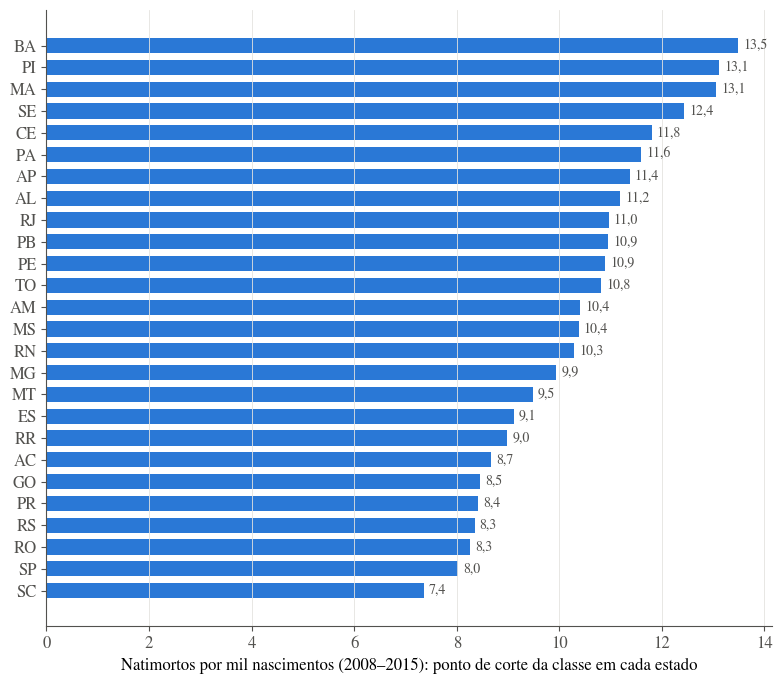

In [3]:
estados = treino.groupby("GRUPO").agg(taxa=("TAXA_UF", "first")).sort_values("taxa")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(estados.index, estados["taxa"], color=AZUL, height=0.7)
for uf, linha in estados.iterrows():
    ax.text(linha["taxa"] + 0.1, uf, f"{linha['taxa']:.1f}".replace(".", ","), va="center", color=CINZA, fontsize=10)
ax.set_xlabel("Natimortos por mil nascimentos (2008–2015): ponto de corte da classe em cada estado")
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar("mod_taxa_por_estado")
plt.show()

### d) Entradas medidas em relação ao estado
Como a saída compara o município com o **seu estado**, as entradas passam pela mesma lógica: cada valor vira
"quantos desvios-padrão o município está acima ou abaixo da média do seu estado" (no mesmo período).
Exemplo: 60% de nascidos pretos ou pardos é um valor alto em Santa Catarina e baixo na Bahia; o que interessa é a posição do município dentro do estado.

Essa transformação usa só as entradas (nunca a saída), então pode ser aplicada a um estado novo sem "espiar" o resultado.

In [4]:
def relativo_ao_estado(dados, colunas):
    por_estado = dados.groupby("GRUPO")[colunas]
    return (dados[colunas] - por_estado.transform("mean")) / por_estado.transform("std")


Z = relativo_ao_estado(treino, list(ENTRADAS) + ["IDHM", "TAXA"])  # entradas de 2008-2015, relativas ao estado
Z_teste = relativo_ao_estado(teste, list(ENTRADAS))               # entradas de 2016-2024 (uso complementar)

exemplo = treino.index[treino["MUNICIPIO"].eq("BELO HORIZONTE")][0]
display(pd.DataFrame({"valor original (2008–2015)": treino.loc[exemplo, list(ENTRADAS)].astype(float).round(2),
                      "relativo ao estado (desvios-padrão)": Z.loc[exemplo, list(ENTRADAS)].round(2)})
        .rename(index=ENTRADAS).rename_axis("Belo Horizonte"))

,valor original (2008–2015),relativo ao estado (desvios-padrão)
Belo Horizonte,,
Mães com < 8 anos de estudo,14.76,-2.39
Mães adolescentes,11.91,-1.75
Mães com 35 anos ou mais,18.32,2.44
Nascidos pretos ou pardos,61.55,0.21
Pré-natal com 7+ consultas,75.41,0.53
Pré-natal iniciado no 1º trim.,84.23,0.42
Pré-natal adequado (Kotelchuck),78.55,0.16
Partos cesáreos,50.23,-0.26
Equipes de SF por 10 mil hab.,2.18,-0.99


## 2. Seleção de variáveis
Toda a seleção usa **só o período de treino (2008–2015)**. O período de teste não participa de nenhuma escolha.

### a) Filtro: cada entrada, sozinha, distingue as classes?
A saída é qualitativa (2 classes) e as entradas são quantitativas. Para esse caso, o teste indicado é a **ANOVA (teste F)**:
compara a média da entrada entre as classes. Com duas classes, equivale ao teste t.

O **qui-quadrado** serve para duas variáveis qualitativas. Para usá-lo aqui, cada entrada é dividida em quatro faixas (quartis),
e testa-se se a proporção de municípios "alta" muda entre as faixas. Os dois testes aparecem na tabela; uma entrada passa no filtro se p < 0,05 na ANOVA.

,média (não alta),média (alta),F (ANOVA),p (ANOVA),qui-quadrado,p (qui-quadrado),% alta no Q1,% alta no Q4,passa no filtro
entrada,,,,,,,,,
Partos cesáreos,0.1952,-0.1747,197.2954,0.0000,160.4528,0.0000,65.5891,42.9907,True
Pré-natal com 7+ consultas,0.1443,-0.1291,106.1424,0.0000,102.2599,0.0000,62.5718,44.1409,True
Mães com < 8 anos de estudo,-0.1396,0.1249,99.2354,0.0000,80.8418,0.0000,43.8937,59.8850,True
Pré-natal iniciado no 1º trim.,0.1321,-0.1182,88.6680,0.0000,74.3758,0.0000,60.9914,45.5787,True
Pré-natal adequado (Kotelchuck),0.1289,-0.1154,84.4197,0.0000,85.0651,0.0000,61.7098,45.4349,True
Mães adolescentes,-0.1276,0.1142,82.6272,0.0000,80.2501,0.0000,43.8218,59.2380,True
Nascidos pretos ou pardos,-0.1217,0.1089,75.0832,0.0000,97.9880,0.0000,47.3420,63.3357,True
Mães com 35 anos ou mais,0.0354,-0.0316,6.2578,0.0124,7.2904,0.0632,52.4425,49.9641,True
População (log10),0.0172,-0.0154,1.4784,0.2241,14.7233,0.0021,49.7126,51.6175,False


Passam no filtro: 8 de 10 entradas


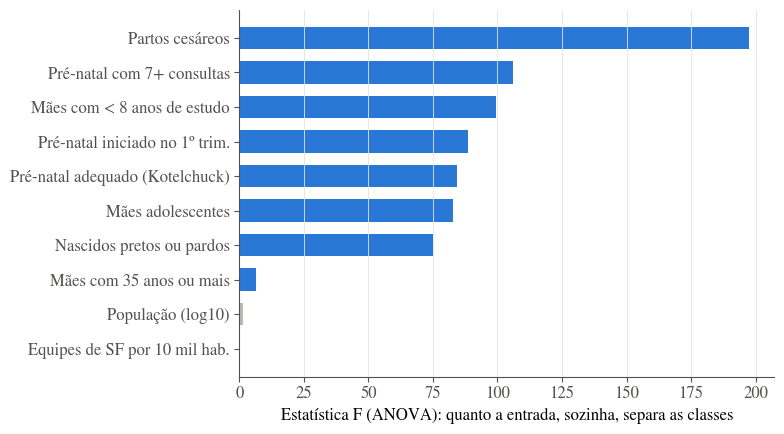

In [5]:
F, p_anova = f_classif(Z[list(ENTRADAS)], y)
linhas = []
for coluna, f_valor, p_f in zip(ENTRADAS, F, p_anova):
    faixas = pd.qcut(Z[coluna], 4, labels=["Q1", "Q2", "Q3", "Q4"])
    qui2, p_qui2, _, _ = stats.chi2_contingency(pd.crosstab(faixas, y))
    pct_alta = y.groupby(faixas, observed=True).mean() * 100
    linhas.append({"entrada": ENTRADAS[coluna], "coluna": coluna,
                   "média (não alta)": Z.loc[y == 0, coluna].mean(), "média (alta)": Z.loc[y == 1, coluna].mean(),
                   "F (ANOVA)": f_valor, "p (ANOVA)": p_f, "qui-quadrado": qui2, "p (qui-quadrado)": p_qui2,
                   "% alta no Q1": pct_alta["Q1"], "% alta no Q4": pct_alta["Q4"]})
filtro = pd.DataFrame(linhas).set_index("entrada").sort_values("F (ANOVA)", ascending=False)
filtro["passa no filtro"] = filtro["p (ANOVA)"] < 0.05
display(filtro.drop(columns="coluna").round(4))
CANDIDATAS = filtro.loc[filtro["passa no filtro"], "coluna"].tolist()
print(f"Passam no filtro: {len(CANDIDATAS)} de {len(ENTRADAS)} entradas")

fig, ax = plt.subplots(figsize=(8, 4.5))
ordem = filtro.sort_values("F (ANOVA)")
ax.barh(ordem.index, ordem["F (ANOVA)"], color=[AZUL if ok else "#b9b8b2" for ok in ordem["passa no filtro"]], height=0.65)
ax.set_xlabel("Estatística F (ANOVA): quanto a entrada, sozinha, separa as classes")
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar("mod_filtro_anova")
plt.show()

### b) As entradas se repetem entre si?
Entradas muito correlacionadas trazem a mesma informação. A matriz de correlação ajuda a entender o que a seleção progressiva fará a seguir.

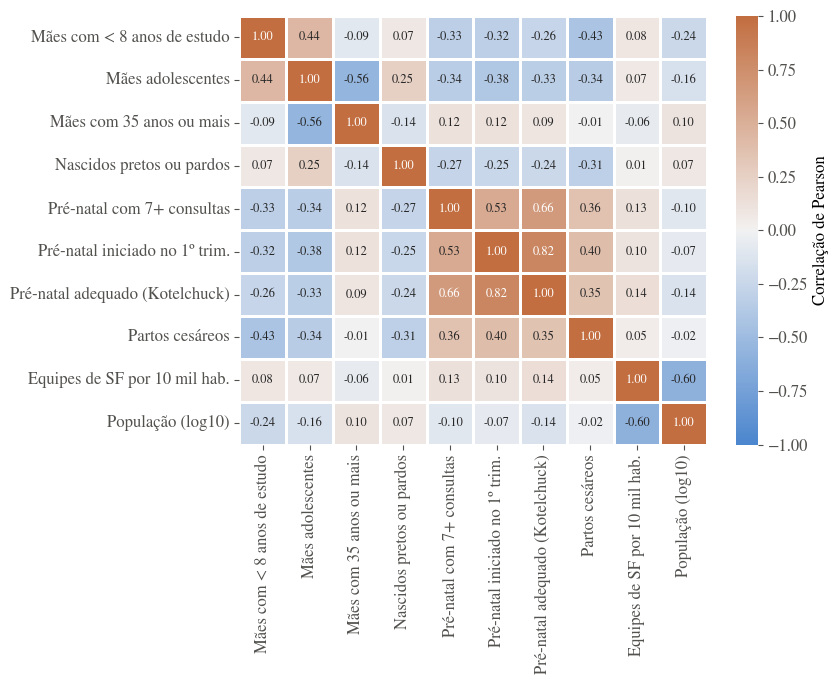

In [6]:
correlacao = Z[list(ENTRADAS)].corr().rename(index=ENTRADAS, columns=ENTRADAS)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(correlacao, annot=True, fmt=".2f", vmin=-1, vmax=1, annot_kws={"size": 9},
            cmap=sns.diverging_palette(250, 30, l=55, center="light", as_cmap=True),
            linewidths=2, linecolor="white", cbar_kws={"label": "Correlação de Pearson"}, ax=ax)
ax.grid(False)
plt.tight_layout()
salvar("mod_correlacao_entradas")
plt.show()

### c) Seleção progressiva (*forward selection*)
Começa sem nenhuma entrada e, a cada passo, acrescenta a que mais aumenta o desempenho do modelo.
O desempenho é medido **dentro do período de treino**, pela AUC na validação que deixa um estado de fora (explicada na seção 3):
uma entrada só entra se ajudar em estados que o modelo não viu.

Regra de parada: a seleção termina quando a melhor entrada disponível aumenta a AUC em menos de 0,002.

,entrada acrescentada,AUC no treino,ganho,entra
passo,,,,
1,Partos cesáreos,0.6066,0.1066,True
2,Pré-natal com 7+ consultas,0.6146,0.0080,True
3,Mães com < 8 anos de estudo,0.6172,0.0026,True
4,Nascidos pretos ou pardos,0.6179,0.0007,False
5,Pré-natal adequado (Kotelchuck),0.6182,0.0003,False
6,Mães com 35 anos ou mais,0.6180,-0.0002,False
7,Pré-natal iniciado no 1º trim.,0.6174,-0.0006,False
8,Mães adolescentes,0.6165,-0.0009,False


Entradas selecionadas: Partos cesáreos, Pré-natal com 7+ consultas, Mães com < 8 anos de estudo


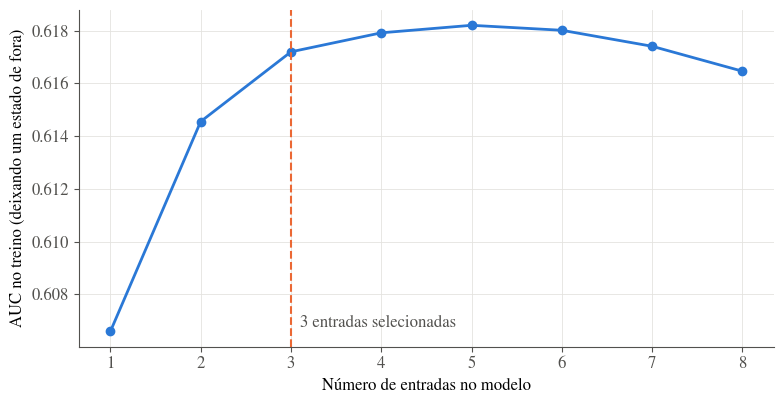

In [7]:
indices_por_estado = {g: idx for g, idx in treino.groupby("GRUPO").groups.items()}
n_por_estado = pd.Series({g: len(idx) for g, idx in indices_por_estado.items()})


def novo_modelo():
    return LogisticRegression(max_iter=1000)


def prever_fora_do_estado(colunas, modelo=None, X_treino=Z, y_treino=y, X_aplicar=None):
    # Para cada estado: treina com os municípios dos OUTROS estados e calcula o risco dos municípios dele.
    # X_aplicar permite calcular o risco com outras entradas (por padrão, as mesmas do treino).
    X_aplicar = X_treino if X_aplicar is None else X_aplicar
    risco = pd.Series(np.nan, index=X_treino.index)
    for estado, idx_estado in indices_por_estado.items():
        outros = grupos != estado
        ajustado = (modelo if modelo is not None else novo_modelo()).fit(X_treino.loc[outros, colunas], y_treino[outros])
        risco[idx_estado] = ajustado.predict_proba(X_aplicar.loc[idx_estado, colunas])[:, 1]
    return risco


def auc_por_estado(prob, classe):
    return pd.Series({g: roc_auc_score(classe[idx], prob[idx]) for g, idx in indices_por_estado.items()})


def auc_media(prob, classe, selecao=None):
    # Média das AUCs dos estados, ponderada pelo número de municípios (opcional: só parte dos municípios)
    partes = []
    for idx in indices_por_estado.values():
        if selecao is not None:
            idx = idx[selecao[idx].to_numpy()]
        if len(idx) and classe[idx].nunique() == 2:
            partes.append((roc_auc_score(classe[idx], prob[idx]), len(idx)))
    return np.average([a for a, _ in partes], weights=[n for _, n in partes])


GANHO_MINIMO = 0.002
selecionadas, restantes, passos, auc_atual = [], list(CANDIDATAS), [], 0.5
while restantes:
    tentativas = {coluna: auc_media(prever_fora_do_estado(selecionadas + [coluna]), y) for coluna in restantes}
    melhor = max(tentativas, key=tentativas.get)
    ganho = tentativas[melhor] - auc_atual
    passos.append({"passo": len(passos) + 1, "entrada acrescentada": ENTRADAS[melhor], "coluna": melhor,
                   "AUC no treino": tentativas[melhor], "ganho": ganho})
    selecionadas.append(melhor)
    restantes.remove(melhor)
    auc_atual = tentativas[melhor]
passos = pd.DataFrame(passos).set_index("passo")
# a seleção para no primeiro passo com ganho menor que o mínimo
pequeno = passos["ganho"] < GANHO_MINIMO
n_selecionadas = int(pequeno.idxmax() - 1) if pequeno.any() else len(passos)
passos["entra"] = passos.index <= n_selecionadas
SELECIONADAS = passos.loc[passos["entra"], "coluna"].tolist()
display(passos.drop(columns="coluna").round(4))
print("Entradas selecionadas:", ", ".join(ENTRADAS[c] for c in SELECIONADAS))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(passos.index, passos["AUC no treino"], color=AZUL, lw=2, marker="o", ms=6)
ax.axvline(n_selecionadas, color=LARANJA, ls="--", lw=1.5)
ax.text(n_selecionadas + 0.1, passos["AUC no treino"].min(), f"{n_selecionadas} entradas selecionadas", color=CINZA, va="bottom")
ax.set_xticks(passos.index)
ax.set(xlabel="Número de entradas no modelo", ylabel="AUC no treino (deixando um estado de fora)")
plt.tight_layout()
salvar("mod_selecao_progressiva")
plt.show()

## 3. Modelo: regressão logística, treino e teste

### a) Por que regressão logística
- **A saída é qualitativa com duas classes**, que é exatamente o caso da regressão logística: ela estima a probabilidade de o município ser "alta".
- **É o modelo mais simples** que resolve o problema, e os coeficientes têm leitura direta (razões de chances), o que importa para explicar o resultado a gestores.
- **Generaliza tão bem quanto modelos mais flexíveis**: a tabela abaixo compara, com as mesmas entradas e ainda dentro do período de treino, a regressão logística com outros classificadores.

### b) Como o modelo é treinado e testado: dois cortes
O conjunto de teste é separado do treino de **duas formas ao mesmo tempo**:

| Corte | Treino | Teste | Pergunta que responde |
|---|---|---|---|
| **No tempo** | entradas e rótulo de 2008–2015 | rótulo de 2016–2024 | O modelo acerta o que acontece **depois**? |
| **No espaço** | municípios de todos os outros estados | municípios do estado que ficou de fora | O modelo funciona em um estado **novo**? |

O procedimento, repetido para cada um dos 26 estados (o DF fica com Goiás):

1. separa-se um estado;
2. treina-se a regressão logística com os municípios dos **outros 25 estados**, usando as entradas e o rótulo de **2008–2015**;
3. calcula-se o risco dos municípios do estado separado, a partir das entradas dele em **2008–2015**;
4. compara-se esse risco com o rótulo que o município teve em **2016–2024**.

É uma validação cruzada em que cada parte é um estado inteiro (*leave-one-group-out*). Ela é mais exigente que o k-fold comum,
que misturaria municípios do mesmo estado no treino e no teste. No fim, todo município tem um risco previsto por um modelo que
nunca viu o seu estado e que só usou informação anterior ao período de teste.

A medida de desempenho é a **AUC** (área sob a curva ROC), calculada dentro de cada estado: é a probabilidade de o modelo dar risco maior a um
município "alta" do que a um "não alta" escolhidos ao acaso. 0,5 = chute; 1,0 = ordenação perfeita.

### c) Por que cortar em 2008–2015 e 2016–2024
O rótulo de um município depende de quantos óbitos fetais ele teve no período. Quanto **menos anos** no período, mais o rótulo depende do acaso,
principalmente nos municípios pequenos. Por isso o período de teste precisa ser longo: se o rótulo do teste for ruidoso, nenhum modelo parece bom,
mesmo que esteja certo.

Dividir os dados ao meio dá a treino e teste quase o mesmo número de anos (8 e 9), de nascimentos e de óbitos, e rótulos com confiabilidade parecida.
Antes de fixar o desenho, foram exploradas outras divisões (fora deste notebook):

| Divisão | Anos de treino / teste | Municípios sem nenhum óbito fetal no período de teste |
|---|---|---|
| **2008–2015 → 2016–2024 (adotada)** | 8 / 9 | cerca de 150 |
| 2008–2020 → 2021–2024 | 13 / 4 | cerca de 520 |
| 2008–2023 → 2024 | 16 / 1 | cerca de 1.970 |

Com 4 anos de teste, um em cada dez municípios não tem nenhum óbito fetal no período; com 1 ano, mais de um terço. Nesses casos o rótulo "não alta"
diz pouco sobre o risco real do município. A divisão ao meio também combina com o uso pretendido: o planejamento em saúde é feito para vários anos, e não ano a ano.

Pontos de atenção:
- a divisão foi escolhida depois dessa exploração, e não antes de olhar os dados; a seleção de variáveis e o ajuste do modelo, porém, usam só 2008–2015;
- o período de teste inclui os anos da pandemia de covid-19 (2020 e 2021).

In [8]:
comparacao_modelos = pd.DataFrame([
    {"modelo": nome, "AUC no treino (um estado de fora)": auc_media(prever_fora_do_estado(SELECIONADAS, modelo), y)}
    for nome, modelo in {
        "Regressão logística": novo_modelo(),
        "Naive Bayes": GaussianNB(),
        "KNN (k = 55)": KNeighborsClassifier(n_neighbors=55),
        "Árvore de decisão (profundidade 4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=50,
                                                                    random_state=SEMENTE),
    }.items()]).set_index("modelo")
display(comparacao_modelos.round(3))

,AUC no treino (um estado de fora)
modelo,
Regressão logística,0.617
Naive Bayes,0.617
KNN (k = 55),0.597
Árvore de decisão (profundidade 4),0.594


## 4. Resultados do teste
Aqui o período de teste entra pela primeira vez. O risco de cada município foi calculado com as entradas de 2008–2015,
por um modelo treinado sem o estado dele, e é comparado com o rótulo de **2016–2024**.

### a) AUC em cada estado
Estados com poucos municípios (Roraima, Amapá, Acre) têm AUC muito instável.

,estados,municipios,AUC no teste
regiao,,,
Norte,7.0,449.0,0.595
Nordeste,9.0,1794.0,0.613
Sudeste,4.0,1668.0,0.633
Sul,3.0,1188.0,0.615
Centro-Oeste,3.0,466.0,0.676
Brasil,26.0,5565.0,0.623


AUC no teste (rótulo de 2016-2024): 0.623
Para comparar, AUC no próprio período de treino (rótulo de 2008-2015): 0.617


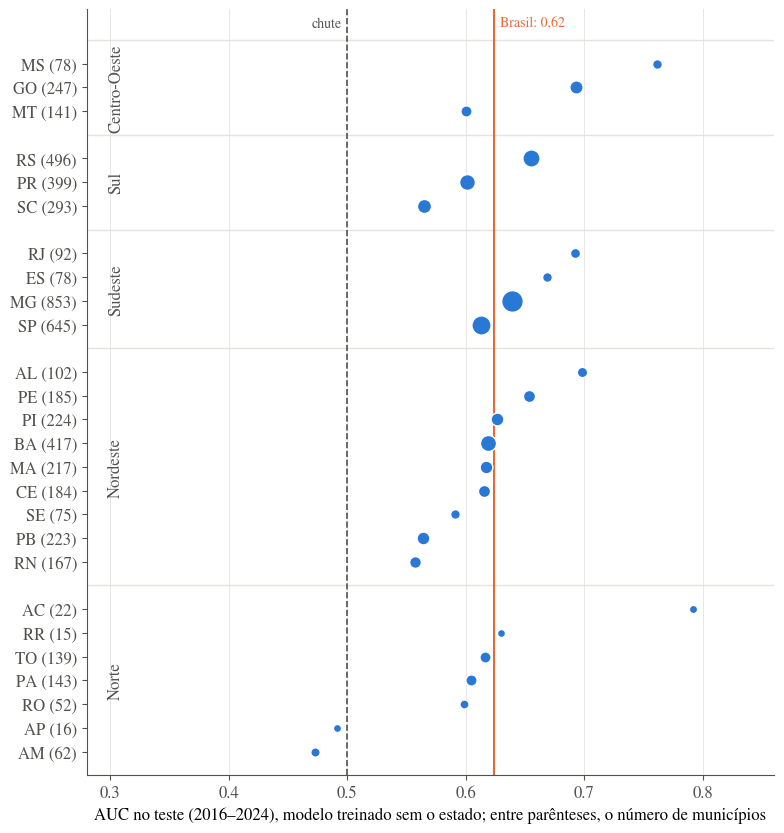

In [9]:
risco = prever_fora_do_estado(SELECIONADAS)  # previsão: modelo e entradas de 2008-2015, estado fora do treino

aucs = auc_por_estado(risco, y_teste)
tabela_estados = pd.DataFrame({"regiao": treino.groupby("GRUPO")["REGIAO"].first(), "municipios": n_por_estado,
                               "AUC": aucs})
tabela_estados["regiao"] = pd.Categorical(tabela_estados["regiao"], ORDEM_REGIOES, ordered=True)
tabela_estados = tabela_estados.sort_values(["regiao", "AUC"])
AUC_TESTE = auc_media(risco, y_teste)
AUC_TREINO = auc_media(risco, y)

resumo_regioes = tabela_estados.groupby("regiao", observed=True).apply(
    lambda d: pd.Series({"estados": len(d), "municipios": d["municipios"].sum(),
                         "AUC no teste": np.average(d["AUC"], weights=d["municipios"])}), include_groups=False)
resumo_regioes.loc["Brasil"] = [len(tabela_estados), tabela_estados["municipios"].sum(), AUC_TESTE]
display(resumo_regioes.round(3))
print(f"AUC no teste (rótulo de 2016-2024): {AUC_TESTE:.3f}")
print(f"Para comparar, AUC no próprio período de treino (rótulo de 2008-2015): {AUC_TREINO:.3f}")

fig, ax = plt.subplots(figsize=(8, 8.5))
posicao, rotulos, y_pos = 0, [], []
for regiao in ORDEM_REGIOES:
    bloco = tabela_estados[tabela_estados["regiao"] == regiao]
    for uf, linha in bloco.iterrows():
        ax.scatter(linha["AUC"], posicao, s=30 + 0.25 * linha["municipios"], color=AZUL, zorder=3,
                   edgecolors="white", linewidths=1)
        rotulos.append(f"{uf} ({int(linha['municipios'])})")
        y_pos.append(posicao)
        posicao += 1
    ax.text(0.305, posicao - len(bloco) / 2 - 0.5, regiao, rotation=90, va="center", ha="center", color=CINZA)
    ax.axhline(posicao, color="#e4e3df", lw=1)
    posicao += 1
ax.axvline(0.5, color=CINZA, ls="--", lw=1.2)
ax.axvline(AUC_TESTE, color=LARANJA, lw=1.5)
ax.text(0.495, posicao - 0.6, "chute", color=CINZA, ha="right", va="bottom", fontsize=10)
ax.text(AUC_TESTE + 0.005, posicao - 0.6, f"Brasil: {AUC_TESTE:.2f}".replace(".", ","), color=LARANJA, ha="left",
        va="bottom", fontsize=10)
ax.set_yticks(y_pos, rotulos)
ax.set_xlim(0.28, max(0.86, tabela_estados["AUC"].max() + 0.03))
ax.set_ylim(-1, posicao + 0.3)
ax.set_xlabel("AUC no teste (2016–2024), modelo treinado sem o estado; entre parênteses, o número de municípios")
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar("mod_auc_por_estado")
plt.show()

### b) Classificação com o corte ajustado ao estado
Para transformar o risco em rótulo previsto, o município é classificado como "alta" quando seu risco está entre os maiores do estado,
na mesma proporção de municípios "alta" observada nos **estados de treino** (em 2008–2015). A tabela mostra também o corte fixo em 0,5
e a referência de sempre escolher a classe mais comum.

,acurácia,precisão,recall,F1
corte,,,,
Ajustado ao estado,0.586,0.601,0.612,0.607
"Fixo em 0,5",0.586,0.590,0.671,0.628
Referência: sempre a classe mais comum no treino,0.521,0.521,1.000,0.685


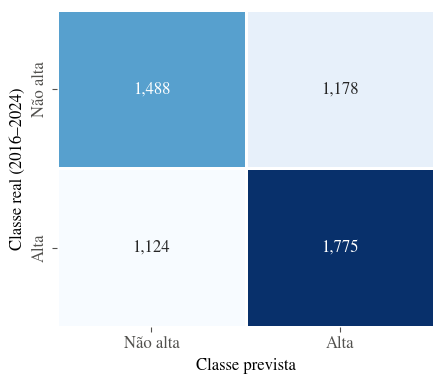

In [10]:
def metricas(previsto, nome):
    return {"corte": nome, "acurácia": accuracy_score(y_teste, previsto), "precisão": precision_score(y_teste, previsto),
            "recall": recall_score(y_teste, previsto), "F1": f1_score(y_teste, previsto)}


proporcao_alta_treino = grupos.map({g: y[grupos != g].mean() for g in indices_por_estado})
posto = risco.groupby(grupos).rank(pct=True)  # posição do município dentro do estado (0 a 1)
previsto_ajustado = (posto > 1 - proporcao_alta_treino).astype(int)
previsto_fixo = (risco >= 0.5).astype(int)
maioria = pd.Series(int(y.mean() >= 0.5), index=y.index)
display(pd.DataFrame([metricas(previsto_ajustado, "Ajustado ao estado"), metricas(previsto_fixo, "Fixo em 0,5"),
                      metricas(maioria, "Referência: sempre a classe mais comum no treino")]).set_index("corte").round(3))

matriz = confusion_matrix(y_teste, previsto_ajustado)
fig, ax = plt.subplots(figsize=(4.6, 4))
sns.heatmap(matriz, annot=True, fmt=",d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["Não alta", "Alta"], yticklabels=["Não alta", "Alta"], ax=ax)
ax.set(xlabel="Classe prevista", ylabel="Classe real (2016–2024)")
ax.grid(False)
plt.tight_layout()
salvar("mod_matriz_confusao")
plt.show()

### c) O modelo ordena os municípios pelo risco?
Dentro de cada estado, os municípios são divididos em cinco faixas de risco previsto (1 = menor, 5 = maior).
Se o modelo funciona, a taxa **observada em 2016–2024** sobe da faixa 1 para a 5. Duas formas de medir:
- **(a) cada município vale igual:** média das taxas dos municípios da faixa;
- **(b) ponderado pelos nascimentos:** soma dos óbitos ÷ soma dos nascimentos da faixa (as cidades grandes pesam mais).

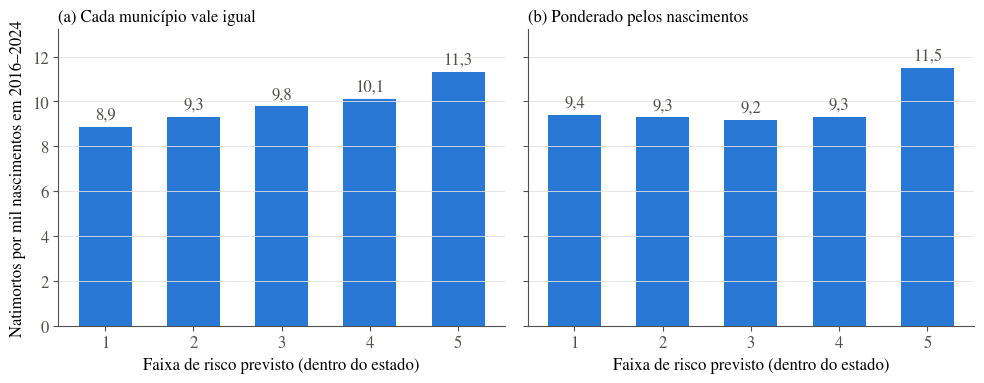

Razão entre a faixa 5 e a faixa 1: {'por município': 1.28, 'por nascimentos': 1.22}


In [11]:
def taxa_por_faixa(prob, dados=teste):
    # Taxa observada em `dados` por faixa de risco previsto (faixas formadas dentro de cada estado)
    faixa = prob.groupby(grupos).transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False)) + 1
    por_faixa = dados.groupby(faixa)
    return pd.DataFrame({"por município": por_faixa["TAXA"].mean(),
                         "por nascimentos": 1000 * por_faixa["OBITOS_FETAIS"].sum() / por_faixa["NASCIMENTOS"].sum()})


def razao_entre_faixas(prob):
    faixas = taxa_por_faixa(prob)
    return faixas.iloc[-1] / faixas.iloc[0]


faixas_modelo = taxa_por_faixa(risco)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, coluna, titulo in zip(eixos, faixas_modelo.columns, ["(a) Cada município vale igual", "(b) Ponderado pelos nascimentos"]):
    barras = ax.bar(faixas_modelo.index.astype(str), faixas_modelo[coluna], color=AZUL, width=0.6)
    ax.bar_label(barras, labels=[f"{v:.1f}".replace(".", ",") for v in faixas_modelo[coluna]], padding=3, color=CINZA)
    ax.set_title(titulo, loc="left", fontsize=12)
    ax.set_xlabel("Faixa de risco previsto (dentro do estado)")
    ax.grid(axis="x", visible=False)
eixos[0].set_ylabel("Natimortos por mil nascimentos em 2016–2024")
eixos[0].set_ylim(0, faixas_modelo.max().max() * 1.15)
plt.tight_layout()
salvar("mod_taxa_por_faixa")
plt.show()
print("Razão entre a faixa 5 e a faixa 1:", razao_entre_faixas(risco).round(2).to_dict())

### d) Verificações complementares
- **Municípios com mais nascimentos:** nos municípios pequenos, o rótulo ainda depende de poucos óbitos. Avaliando só os que têm pelo menos
  700 nascimentos em 2016–2024, o rótulo é mais confiável.
- **Mesmo modelo, entradas atualizadas:** em vez das entradas de 2008–2015, o modelo recebe as de 2016–2024. Mostra se as relações aprendidas continuam valendo.
- **Teto do período:** um modelo treinado e avaliado dentro de 2016–2024 (ainda deixando um estado de fora). É o máximo que essas entradas
  conseguem neste período; a distância entre a previsão e o teto mostra quanto se perde por só conhecer o passado.

In [12]:
maiores = teste["NASCIMENTOS"] >= 700
risco_entradas_novas = prever_fora_do_estado(SELECIONADAS, X_aplicar=Z_teste)
risco_teto = prever_fora_do_estado(SELECIONADAS, X_treino=Z_teste, y_treino=y_teste)

complementar = pd.DataFrame({
    "AUC (todos)": {nome: auc_media(p, y_teste) for nome, p in {
        "Previsão: modelo e entradas de 2008–2015": risco,
        "Mesmo modelo com entradas de 2016–2024": risco_entradas_novas,
        "Teto do período (treinado em 2016–2024)": risco_teto}.items()},
    f"AUC (≥ 700 nascimentos; {maiores.sum():,} municípios)": {nome: auc_media(p, y_teste, maiores) for nome, p in {
        "Previsão: modelo e entradas de 2008–2015": risco,
        "Mesmo modelo com entradas de 2016–2024": risco_entradas_novas,
        "Teto do período (treinado em 2016–2024)": risco_teto}.items()},
})
display(complementar.round(3))
AUC_MAIORES = auc_media(risco, y_teste, maiores)

,AUC (todos),"AUC (≥ 700 nascimentos; 3,818 municípios)"
Previsão: modelo e entradas de 2008–2015,0.623,0.648
Mesmo modelo com entradas de 2016–2024,0.618,0.640
Teto do período (treinado em 2016–2024),0.624,0.648


## 5. Testes estatísticos de explicação do modelo
Na regressão linear, usam-se o **teste F** (o modelo como um todo é útil?) e o **teste t** (cada coeficiente é diferente de zero?).
Na regressão logística, o ajuste é por máxima verossimilhança, e os testes equivalentes são:

| Regressão linear | Regressão logística | Pergunta |
|---|---|---|
| Teste F (ANOVA) | **Teste da razão de verossimilhança** (qui-quadrado) | O modelo com as entradas é melhor do que um modelo sem nenhuma? |
| Teste t | **Teste de Wald** (z) | Cada coeficiente é diferente de zero? |
| Soma de quadrados por variável (ANOVA) | **Análise de desvio**: razão de verossimilhança retirando uma entrada | O modelo piora se essa entrada sair? |
| R² | **Pseudo-R² de McFadden** | Quanto o modelo melhora em relação ao modelo vazio? |

Aqui o modelo é ajustado com **todos os municípios, no período de treino (2008–2015)**: o objetivo desta seção é explicar, não prever.
Como as entradas estão em desvios-padrão, cada coeficiente vira uma **razão de chances por desvio-padrão**:
acima de 1, a entrada aumenta a chance de "alta"; abaixo de 1, diminui.

TESTE GLOBAL (razão de verossimilhança, equivalente ao teste F)
  Qui-quadrado = 238.0 com 3 graus de liberdade; p-valor = 2.61e-51
  Pseudo-R² de McFadden = 0.0309


,coeficiente,razão de chances,IC95% inf,IC95% sup,z (Wald),p (Wald),qui-quadrado (sem a entrada),p (razão de verossimilhança)
Partos cesáreos,-0.2879,0.7499,0.7046,0.7981,-9.0553,0.0000,83.4862,0.0000
Pré-natal com 7+ consultas,-0.1485,0.8620,0.8122,0.9148,-4.8920,0.0000,24.0686,0.0000
Mães com < 8 anos de estudo,0.1068,1.1127,1.0468,1.1828,3.4266,0.0006,11.7822,0.0006


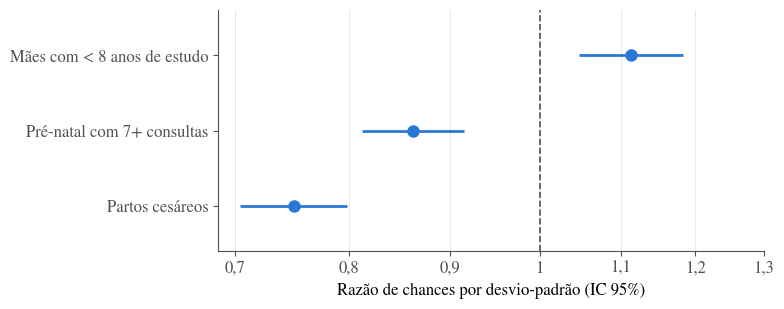

In [13]:
X_final = sm.add_constant(Z[SELECIONADAS])
logit = sm.Logit(y, X_final).fit(disp=False)
print("TESTE GLOBAL (razão de verossimilhança, equivalente ao teste F)")
print(f"  Qui-quadrado = {logit.llr:.1f} com {int(logit.df_model)} graus de liberdade; p-valor = {logit.llr_pvalue:.3g}")
print(f"  Pseudo-R² de McFadden = {logit.prsquared:.4f}")

ic = logit.conf_int().drop("const")
explicacao = pd.DataFrame({
    "coeficiente": logit.params.drop("const"),
    "razão de chances": np.exp(logit.params.drop("const")),
    "IC95% inf": np.exp(ic[0]), "IC95% sup": np.exp(ic[1]),
    "z (Wald)": logit.tvalues.drop("const"), "p (Wald)": logit.pvalues.drop("const"),
})
desvio = []
for coluna in SELECIONADAS:  # análise de desvio: o modelo piora sem esta entrada?
    outras = [c for c in SELECIONADAS if c != coluna]
    X_sem = sm.add_constant(Z[outras]) if outras else pd.DataFrame({"const": 1.0}, index=Z.index)
    sem = sm.Logit(y, X_sem).fit(disp=False)
    estatistica = 2 * (logit.llf - sem.llf)
    desvio.append({"qui-quadrado (sem a entrada)": estatistica, "p (razão de verossimilhança)": stats.chi2.sf(estatistica, 1)})
explicacao = explicacao.join(pd.DataFrame(desvio, index=SELECIONADAS)).rename(index=ENTRADAS)
explicacao = explicacao.sort_values("razão de chances")
display(explicacao.round(4))

fig, ax = plt.subplots(figsize=(8, 0.55 * len(explicacao) + 1.6))
posicoes = np.arange(len(explicacao))
ax.errorbar(explicacao["razão de chances"], posicoes,
            xerr=[explicacao["razão de chances"] - explicacao["IC95% inf"],
                  explicacao["IC95% sup"] - explicacao["razão de chances"]],
            fmt="o", color=AZUL, ecolor=AZUL, elinewidth=2, capsize=0, ms=8)
ax.axvline(1, color=CINZA, ls="--", lw=1.2)
ax.set_xscale("log")
marcas = [0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3]
ax.set_xticks(marcas, [str(m).replace(".", ",") for m in marcas])
ax.minorticks_off()
ax.set_yticks(posicoes, explicacao.index)
ax.set_ylim(-0.6, len(explicacao) - 0.4)
ax.set_xlabel("Razão de chances por desvio-padrão (IC 95%)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar("mod_razao_chances")
plt.show()

## 6. Comparação com as referências: IDHM e taxa passada
Um modelo só é útil se for melhor do que as alternativas simples que o gestor já tem. Duas referências, avaliadas no mesmo teste (rótulo de 2016–2024):

**IDHM.** O Índice de Desenvolvimento Humano Municipal é o indicador composto mais usado para comparar municípios em estudos de saúde no Brasil:
- uma revisão de escopo sobre desigualdades de mortalidade no país encontrou o IDH entre os indicadores socioeconômicos compostos usados nos estudos,
  e associação inversa entre nível socioeconômico e mortalidade fetal e infantil (Ichihara et al., *Rev Saúde Pública*, 2022);
- Boing e Boing (*Cad Saúde Pública*, 2008) mostraram que a mortalidade infantil por causas evitáveis cresce à medida que o IDH municipal diminui;
- Aquino et al. (*Am J Public Health*, 2009) usaram o IDH para estratificar o efeito do Programa Saúde da Família sobre a mortalidade infantil.

A referência é uma regressão logística só com o IDHM de 2010, treinada do mesmo jeito (2008–2015, estado fora do treino).

**Taxa passada do município.** É a regra mais simples possível: "quem teve natimortalidade alta em 2008–2015 continuará tendo".
Os municípios são ordenados pela própria taxa de 2008–2015, sem modelo nenhum.

Também se avalia a **combinação** do modelo com a taxa passada (soma das posições do município nas duas ordenações, dentro do estado).

In [14]:
risco_idhm = prever_fora_do_estado(["IDHM"])
taxa_passada = Z["TAXA"]  # taxa de 2008-2015, relativa ao estado
modelo_mais_taxa = risco.groupby(grupos).rank(pct=True) + taxa_passada.groupby(grupos).rank(pct=True)
risco_sus_idhm = prever_fora_do_estado(SELECIONADAS + ["IDHM"])

ORDENACOES = {"Só IDHM": risco_idhm, "Só a taxa passada": taxa_passada, "Modelo (dados do SUS)": risco,
              "Modelo + taxa passada": modelo_mais_taxa}
comparacao = pd.DataFrame({"regiao": tabela_estados["regiao"], "municipios": n_por_estado,
                           **{nome: auc_por_estado(p, y_teste) for nome, p in ORDENACOES.items()}})
por_regiao_auc = comparacao.groupby("regiao", observed=True).apply(
    lambda d: pd.Series({m: np.average(d[m], weights=d["municipios"]) for m in ORDENACOES}), include_groups=False)
por_regiao_auc.loc["Brasil"] = [np.average(comparacao[m], weights=comparacao["municipios"]) for m in ORDENACOES]
por_regiao_auc.loc["Brasil, ≥ 700 nascimentos"] = [auc_media(p, y_teste, maiores) for p in ORDENACOES.values()]
display(por_regiao_auc.round(3))
print(f"Modelo com dados do SUS + IDHM como entrada: AUC = {auc_media(risco_sus_idhm, y_teste):.3f} "
      f"(sem o IDHM: {AUC_TESTE:.3f})")

# Incerteza das diferenças: reamostragem (bootstrap) dos municípios dentro de cada estado
posicoes_estado = [np.flatnonzero(grupos.to_numpy() == g) for g in indices_por_estado]


def ic_diferenca(prob_1, prob_2, repeticoes=1000):
    rng = np.random.default_rng(SEMENTE)
    c, p1, p2 = y_teste.to_numpy(), prob_1.to_numpy(), prob_2.to_numpy()
    diferencas = []
    for _ in range(repeticoes):
        soma_1 = soma_2 = total = 0
        for pos in posicoes_estado:
            amostra = rng.choice(pos, len(pos))
            if c[amostra].min() == c[amostra].max():
                continue
            soma_1 += len(amostra) * roc_auc_score(c[amostra], p1[amostra])
            soma_2 += len(amostra) * roc_auc_score(c[amostra], p2[amostra])
            total += len(amostra)
        diferencas.append((soma_1 - soma_2) / total)
    return {"diferença de AUC": auc_media(prob_1, y_teste) - auc_media(prob_2, y_teste),
            "IC95% inf": np.percentile(diferencas, 2.5), "IC95% sup": np.percentile(diferencas, 97.5)}


diferencas = pd.DataFrame({
    "Modelo − IDHM": ic_diferenca(risco, risco_idhm),
    "Modelo − taxa passada": ic_diferenca(risco, taxa_passada),
    "(Modelo + taxa passada) − taxa passada": ic_diferenca(modelo_mais_taxa, taxa_passada),
}).T
diferencas["estados em que ganha"] = [int((comparacao["Modelo (dados do SUS)"] > comparacao["Só IDHM"]).sum()),
                                      int((comparacao["Modelo (dados do SUS)"] > comparacao["Só a taxa passada"]).sum()),
                                      int((comparacao["Modelo + taxa passada"] > comparacao["Só a taxa passada"]).sum())]
display(diferencas.round(3))
print(f"(total de estados: {len(comparacao)})")

,Só IDHM,Só a taxa passada,Modelo (dados do SUS),Modelo + taxa passada
regiao,,,,
Norte,0.552,0.554,0.595,0.601
Nordeste,0.583,0.579,0.613,0.624
Sudeste,0.593,0.599,0.633,0.646
Sul,0.574,0.566,0.615,0.615
Centro-Oeste,0.648,0.601,0.676,0.675
Brasil,0.587,0.582,0.623,0.631
"Brasil, ≥ 700 nascimentos",0.612,0.618,0.648,0.666


Modelo com dados do SUS + IDHM como entrada: AUC = 0.624 (sem o IDHM: 0.623)


,diferença de AUC,IC95% inf,IC95% sup,estados em que ganha
Modelo − IDHM,0.036,0.022,0.050,19
Modelo − taxa passada,0.041,0.022,0.061,19
(Modelo + taxa passada) − taxa passada,0.049,0.039,0.059,24


(total de estados: 26)


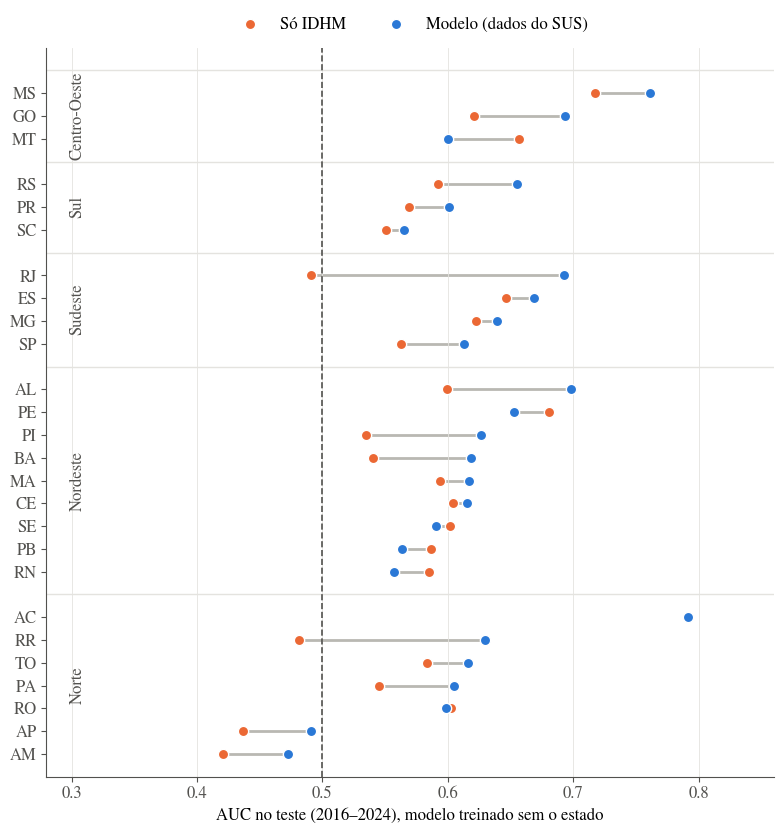

In [15]:
ordenado = comparacao.sort_values(["regiao", "Modelo (dados do SUS)"])
fig, ax = plt.subplots(figsize=(8, 8.5))
posicao, rotulos, y_pos = 0, [], []
for regiao in ORDEM_REGIOES:
    bloco = ordenado[ordenado["regiao"] == regiao]
    for uf, linha in bloco.iterrows():
        ax.plot([linha["Só IDHM"], linha["Modelo (dados do SUS)"]], [posicao, posicao], color="#b9b8b2", lw=2, zorder=1)
        ax.scatter(linha["Só IDHM"], posicao, s=55, color=LARANJA, zorder=3, edgecolors="white", linewidths=1,
                   label="Só IDHM" if posicao == 0 else None)
        ax.scatter(linha["Modelo (dados do SUS)"], posicao, s=55, color=AZUL, zorder=3, edgecolors="white", linewidths=1,
                   label="Modelo (dados do SUS)" if posicao == 0 else None)
        rotulos.append(uf)
        y_pos.append(posicao)
        posicao += 1
    ax.text(0.305, posicao - len(bloco) / 2 - 0.5, regiao, rotation=90, va="center", ha="center", color=CINZA)
    ax.axhline(posicao, color="#e4e3df", lw=1)
    posicao += 1
ax.axvline(0.5, color=CINZA, ls="--", lw=1.2)
ax.set_yticks(y_pos, rotulos)
ax.set_xlim(0.28, max(0.86, ordenado[["Só IDHM", "Modelo (dados do SUS)"]].max().max() + 0.03))
ax.set_ylim(-1, posicao)
ax.set_xlabel("AUC no teste (2016–2024), modelo treinado sem o estado")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar("mod_sus_versus_idhm")
plt.show()

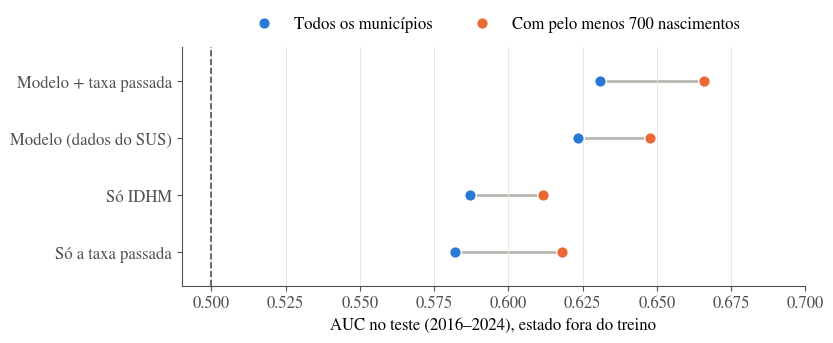

Quanto a taxa observada em 2016-2024 é maior na faixa de maior risco do que na de menor risco:


,faixa 5 ÷ faixa 1 (por município),faixa 5 ÷ faixa 1 (por nascimentos)
Só IDHM,1.17,1.27
Só a taxa passada,1.17,1.31
Modelo (dados do SUS),1.28,1.22
Modelo + taxa passada,1.28,1.27


In [16]:
resumo_ordenacoes = pd.DataFrame({
    "AUC (todos)": {nome: auc_media(p, y_teste) for nome, p in ORDENACOES.items()},
    "AUC (≥ 700 nascimentos)": {nome: auc_media(p, y_teste, maiores) for nome, p in ORDENACOES.items()},
}).sort_values("AUC (todos)")
fig, ax = plt.subplots(figsize=(8.5, 3.6))
posicoes = np.arange(len(resumo_ordenacoes))
for pos, (nome, linha) in zip(posicoes, resumo_ordenacoes.iterrows()):
    ax.plot([linha["AUC (todos)"], linha["AUC (≥ 700 nascimentos)"]], [pos, pos], color="#b9b8b2", lw=2, zorder=1)
ax.scatter(resumo_ordenacoes["AUC (todos)"], posicoes, s=70, color=AZUL, zorder=3, edgecolors="white", linewidths=1,
           label="Todos os municípios")
ax.scatter(resumo_ordenacoes["AUC (≥ 700 nascimentos)"], posicoes, s=70, color=LARANJA, zorder=3, edgecolors="white",
           linewidths=1, label="Com pelo menos 700 nascimentos")
ax.axvline(0.5, color=CINZA, ls="--", lw=1.2)
ax.set_yticks(posicoes, resumo_ordenacoes.index)
ax.set_xlim(0.49, max(0.70, resumo_ordenacoes.max().max() + 0.02))
ax.set_ylim(-0.6, len(resumo_ordenacoes) - 0.4)
ax.set_xlabel("AUC no teste (2016–2024), estado fora do treino")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
salvar("mod_comparacao_referencias")
plt.show()

gradiente = pd.DataFrame({nome: razao_entre_faixas(p) for nome, p in ORDENACOES.items()}).T
gradiente.columns = ["faixa 5 ÷ faixa 1 (por município)", "faixa 5 ÷ faixa 1 (por nascimentos)"]
print("Quanto a taxa observada em 2016-2024 é maior na faixa de maior risco do que na de menor risco:")
display(gradiente.round(2))

## Resumo

In [17]:
pior, melhor = tabela_estados["AUC"].idxmin(), tabela_estados["AUC"].idxmax()
significativas = explicacao[explicacao["p (Wald)"] < 0.05]
dif_idhm, dif_taxa = diferencas.loc["Modelo − IDHM"], diferencas.loc["Modelo − taxa passada"]
print(f"1. Bases: {len(treino):,} municípios; treino em 2008-2015 e teste em 2016-2024; "
      f"{100 * y.mean():.0f}% na classe alta no treino e {100 * y_teste.mean():.0f}% no teste.")
print(f"2. Entradas selecionadas no treino ({len(SELECIONADAS)}): " + ", ".join(ENTRADAS[c] for c in SELECIONADAS) + ".")
print(f"3. Teste (rótulo de 2016-2024, estado fora do treino): AUC = {AUC_TESTE:.3f} "
      f"(de {tabela_estados.loc[pior, 'AUC']:.2f} em {pior} a {tabela_estados.loc[melhor, 'AUC']:.2f} em {melhor}); "
      f"{AUC_MAIORES:.3f} nos municípios com pelo menos 700 nascimentos. "
      f"Teto do período: {complementar.iloc[2, 0]:.3f}.")
print(f"4. Teste global do modelo: qui-quadrado = {logit.llr:.0f}, p = {logit.llr_pvalue:.2g}; "
      f"pseudo-R² = {logit.prsquared:.3f}.")
print("5. Entradas com coeficiente significativo (Wald, p < 0,05): "
      + "; ".join(f"{nome} (RC = {linha['razão de chances']:.2f})" for nome, linha in significativas.iterrows()) + ".")
print(f"6. Referências no teste: IDHM = {por_regiao_auc.loc['Brasil', 'Só IDHM']:.3f}; "
      f"taxa passada = {por_regiao_auc.loc['Brasil', 'Só a taxa passada']:.3f}; "
      f"modelo + taxa passada = {por_regiao_auc.loc['Brasil', 'Modelo + taxa passada']:.3f}.")
print(f"   Ganho do modelo sobre o IDHM: {dif_idhm['diferença de AUC']:+.3f} "
      f"(IC95%: {dif_idhm['IC95% inf']:+.3f} a {dif_idhm['IC95% sup']:+.3f}); "
      f"sobre a taxa passada: {dif_taxa['diferença de AUC']:+.3f} "
      f"(IC95%: {dif_taxa['IC95% inf']:+.3f} a {dif_taxa['IC95% sup']:+.3f}).")

previsoes = pd.DataFrame({
    "MUNICIPIO": treino["MUNICIPIO"], "UF": treino["UF"], "REGIAO": treino["REGIAO"],
    "TAXA_2008_2015": treino["TAXA"], "ALTA_2008_2015": y,
    "RISCO_PREVISTO": risco, "POSICAO_NO_ESTADO": posto, "PREVISTO_ALTA": previsto_ajustado,
    "RISCO_SO_IDHM": risco_idhm,
    "NASCIMENTOS_2016_2024": teste["NASCIMENTOS"], "OBITOS_FETAIS_2016_2024": teste["OBITOS_FETAIS"],
    "TAXA_2016_2024": teste["TAXA"], "ALTA_2016_2024": y_teste,
})
previsoes.round(4).to_csv("previsoes_municipios.csv", sep=";", decimal=",", encoding="utf-8-sig")
print("\nRisco previsto de cada município salvo em previsoes_municipios.csv")

1. Bases: 5,565 municípios; treino em 2008-2015 e teste em 2016-2024; 53% na classe alta no treino e 52% no teste.
2. Entradas selecionadas no treino (3): Partos cesáreos, Pré-natal com 7+ consultas, Mães com < 8 anos de estudo.
3. Teste (rótulo de 2016-2024, estado fora do treino): AUC = 0.623 (de 0.47 em AM a 0.79 em AC); 0.648 nos municípios com pelo menos 700 nascimentos. Teto do período: 0.624.
4. Teste global do modelo: qui-quadrado = 238, p = 2.6e-51; pseudo-R² = 0.031.
5. Entradas com coeficiente significativo (Wald, p < 0,05): Partos cesáreos (RC = 0.75); Pré-natal com 7+ consultas (RC = 0.86); Mães com < 8 anos de estudo (RC = 1.11).
6. Referências no teste: IDHM = 0.587; taxa passada = 0.582; modelo + taxa passada = 0.631.
   Ganho do modelo sobre o IDHM: +0.036 (IC95%: +0.022 a +0.050); sobre a taxa passada: +0.041 (IC95%: +0.022 a +0.061).



Risco previsto de cada município salvo em previsoes_municipios.csv
